# Notebook 05 — V10 SMOTE 900 Checkpoint Verification & Deployment Package

**Mục tiêu:** Tái hiện checkpoint T4 (Feature-Tokenized Multi-Scale CNN + SE + Multi-Head Self-Attention), `SMOTE_900`, `seed=43`, `BENIGN logit bias=1.0` đã xác định trên Pareto Audit **validation**. Không huấn luyện thêm, không dùng nhãn test để chọn checkpoint hoặc bias.

**Input Kaggle:** (1) output Notebook **03B** (`cic_expanded_splits.parquet`, `feature_sets.json`, `experiment_manifest.json`); (2) output Notebook **V10** (`trials/.../best.pt`, `validation_bias_grid.csv`, `validation_best_per_seed.csv`). Hai output phải được gắn dưới **Add Input**. Checkpoint thường nằm sâu trong thư mục `nids_outputs/05_V10_SMOTE_Stability/trials/`.

**Giới hạn:** Đây chỉ là *pilot verification* trên split 03B từng được phân tích nhiều lần. Không dùng làm tuyên bố holdout độc lập hay so sánh final publication.

## 1. Thiết lập và tìm input

In [61]:
from pathlib import Path
import json, hashlib, shutil, gc, sys
import numpy as np, pandas as pd, torch, joblib
from torch import nn
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = None  # gán đường dẫn 03B nếu có nhiều bản
V10_DIR = None   # gán đường dẫn output V10 nếu có nhiều bản
SELECTED_STRATEGY='SMOTE_900'
SELECTED_SEED=43
BENIGN_BIAS=1.0
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTPUT=(Path('/kaggle/working/nids_outputs/05_V10_SMOTE900_Deployment') if Path('/kaggle/working').exists()
        else Path('reports/05_V10_SMOTE900_Deployment'))
OUTPUT.mkdir(parents=True,exist_ok=True)

def find_dirs(marker,override=None):
    if override is not None:
        p=Path(override)
        if not (p/marker).is_file():
            raise FileNotFoundError(f'{marker} not found in {p}')
        return [p.resolve()]
    roots=[Path('/kaggle/input'),Path('/kaggle/working/nids_outputs'),Path('reports')]
    result=[]
    for root in roots:
        if root.exists():
            result.extend(p.parent.resolve() for p in root.rglob(marker))
    return sorted(set(result),key=str)

dataset_candidates=[p for p in find_dirs('cic_expanded_splits.parquet',DATA_DIR)
                    if all((p/x).is_file() for x in ('feature_sets.json','experiment_manifest.json'))]
if len(dataset_candidates)!=1:
    raise RuntimeError(f'Expected exactly one complete 03B source, found {dataset_candidates}. Set DATA_DIR.')
source=dataset_candidates[0]
v10_candidates=[p for p in find_dirs('validation_bias_grid.csv',V10_DIR)
                if (p/'validation_best_per_seed.csv').is_file() and (p/'trials').is_dir()]
if len(v10_candidates)!=1:
    raise RuntimeError(f'Expected exactly one complete V10 source with trials/, found {v10_candidates}. Set V10_DIR.')
v10=v10_candidates[0]
print('03B:',source,'\nV10:',v10,'\nDevice:',DEVICE)

03B: /kaggle/input/datasets/chienvoo/nids-outputs/nids_outputs_backup/nids_outputs/03B_CIC_Feature_Engineering 
V10: /kaggle/working/nids_outputs/05_V10_SMOTE_Stability 
Device: cuda


## 2. Kiểm tra split, feature order và preprocessing

In [62]:
split_file=source/'cic_expanded_splits.parquet'
sha=hashlib.sha256(split_file.read_bytes()).hexdigest()
manifest=json.loads((source/'experiment_manifest.json').read_text(encoding='utf8'))
feature_sets=json.loads((source/'feature_sets.json').read_text(encoding='utf8'))
variant=manifest['validation_selected_feature_set']
features=list(feature_sets[variant]);N_FEATURES=len(features)
df=pd.read_parquet(split_file)
assert {'Label','_binary_label','_split','_duplicate_group'}.issubset(df.columns)
assert len(df)==int(manifest['sample_rows'])
assert df.groupby('_duplicate_group')['_split'].nunique().max()==1
assert len(features)==60 and len(set(features))==60 and set(features).issubset(df.columns)
mask={p:df['_split'].eq(p).to_numpy() for p in ('train','val','test')}
assert all(m.sum()>0 for m in mask.values())
labels=df['Label'].astype(str)
enc=LabelEncoder().fit(labels.loc[mask['train']])
classes=enc.classes_.tolist();K=len(classes)
assert K==15 and set(classes)==set(labels)
y={p:enc.transform(labels.loc[m]).astype(np.int64) for p,m in mask.items()}
benign_idx=int(enc.transform(['BENIGN'])[0]);all_ids=np.arange(K)
raw=df[features].apply(pd.to_numeric,errors='coerce').replace([np.inf,-np.inf],np.nan).astype(np.float32)

# Rebuild train-only preprocessing from V10. Any preprocessor artifact may be used only after compatibility is verified.
imputer=SimpleImputer(strategy='median',keep_empty_features=True)
scaler=StandardScaler()
X={'train':scaler.fit_transform(imputer.fit_transform(raw.loc[mask['train']])).astype(np.float32)}
for p in ('val','test'):
    X[p]=scaler.transform(imputer.transform(raw.loc[mask[p]])).astype(np.float32)
assert all(np.isfinite(x).all() for x in X.values())
assert all(X[p].shape==(mask[p].sum(),N_FEATURES) for p in X)
# When V10 original fitted preprocessor is available, confirm rebuild matches it.
pre_path=v10/'preprocessing.joblib'
if pre_path.exists():
    original=joblib.load(pre_path)
    assert list(original['features'])==features and original['split_sha256']==sha
    assert np.allclose(original['imputer'].statistics_,imputer.statistics_,equal_nan=True)
    assert np.allclose(original['scaler'].mean_,scaler.mean_,atol=1e-6)
    assert np.allclose(original['scaler'].scale_,scaler.scale_,atol=1e-6)
    print('Original V10 preprocessing verified.')
else:
    print('WARNING: Original V10 preprocessing.joblib not found. Rebuilt from train-only source; verify exact environment.')
print('SHA256:',sha,'classes:',K,'features:',N_FEATURES,'sizes:',{p:len(y[p]) for p in y})

Original V10 preprocessing verified.
SHA256: d6d516853f1de28ac8614495bfa37f5bbcc52a0dfedb3caafdfb15415578d152 classes: 15 features: 60 sizes: {'train': 23922, 'val': 7862, 'test': 7409}


## 3. Tái tạo CHÍNH XÁC kiến trúc T4 của V10

In [63]:
class FeatureTokenizer(nn.Module):
 def __init__(self,n_features,d_model):
  super().__init__()
  self.weight=nn.Parameter(torch.empty(n_features,d_model))
  self.bias=nn.Parameter(torch.empty(n_features,d_model))
  nn.init.normal_(self.weight,mean=0.,std=.02)
  nn.init.normal_(self.bias,mean=0.,std=.02)
 def forward(self,x):
  return x.unsqueeze(-1)*self.weight.unsqueeze(0)+self.bias.unsqueeze(0)

class SEChannels(nn.Module):
 def __init__(self,d_model,reduction=8):
  super().__init__()
  hidden=max(8,d_model//reduction)
  self.net=nn.Sequential(nn.Linear(d_model,hidden),nn.GELU(),nn.Linear(hidden,d_model),nn.Sigmoid())
 def forward(self,z):
  # z: B,F,D ; squeeze over feature-token positions
  return z * self.net(z.mean(dim=1)).unsqueeze(1)

class TokenResBlock(nn.Module):
 def __init__(self,d_model,dropout):
  super().__init__()
  self.norm=nn.LayerNorm(d_model)
  self.net=nn.Sequential(nn.Linear(d_model,2*d_model),nn.GELU(),nn.Dropout(dropout),nn.Linear(2*d_model,d_model))
  self.dropout=nn.Dropout(dropout)
 def forward(self,x):return x+self.dropout(self.net(self.norm(x)))

class TokenizedCNNSEAttention(nn.Module):
 def __init__(self,n_features,n_classes,d_model=64,heads=4,dropout=.15,
              use_cnn=True,use_se=True,use_attn=True,use_raw=False):
  super().__init__()
  assert d_model%heads==0
  self.flags={'use_cnn':use_cnn,'use_se':use_se,'use_attn':use_attn,'use_raw':use_raw}
  self.tokenizer=FeatureTokenizer(n_features,d_model)
  self.norm0=nn.Identity()  # preserve scalar feature magnitude before feature mixing
  if use_cnn:
   self.convs=nn.ModuleList([nn.Conv1d(d_model,d_model,k,padding=k//2) for k in (1,3,5)])
   self.conv_fuse=nn.Sequential(nn.Conv1d(3*d_model,d_model,1),nn.GELU())
   self.norm_cnn=nn.LayerNorm(d_model)
  self.se=SEChannels(d_model) if use_se else nn.Identity()
  if use_attn:
   self.attn_norm=nn.LayerNorm(d_model)
   self.mha=nn.MultiheadAttention(d_model,heads,dropout=dropout,batch_first=True)
   self.attn_dropout=nn.Dropout(dropout)
  self.token_mlp=TokenResBlock(d_model,dropout)
  self.pool_gate=nn.Linear(d_model,1)
  rep_dim=3*d_model
  if use_raw:
   self.raw_mlp=nn.Sequential(nn.Linear(n_features,2*d_model),nn.LayerNorm(2*d_model),nn.GELU(),
                              nn.Dropout(dropout),nn.Linear(2*d_model,d_model),nn.GELU())
   rep_dim+=d_model
  self.classifier=nn.Sequential(nn.LayerNorm(rep_dim),nn.Linear(rep_dim,2*d_model),nn.GELU(),
                                nn.Dropout(dropout),nn.Linear(2*d_model,n_classes))
 def forward(self,x):
  z=self.norm0(self.tokenizer(x))
  if self.flags['use_cnn']:
   q=z.transpose(1,2)
   mixed=self.conv_fuse(torch.cat([conv(q) for conv in self.convs],dim=1)).transpose(1,2)
   z=self.norm_cnn(z+mixed)
  z=self.se(z)
  if self.flags['use_attn']:
   q=self.attn_norm(z)
   z=z+self.attn_dropout(self.mha(q,q,q,need_weights=False)[0])
  z=self.token_mlp(z)
  weights=torch.softmax(self.pool_gate(z).squeeze(-1),dim=1)
  attentive=(z*weights.unsqueeze(-1)).sum(dim=1)
  reps=[attentive,z.mean(dim=1),z.amax(dim=1)]
  if self.flags['use_raw']:reps.append(self.raw_mlp(x))
  return self.classifier(torch.cat(reps,dim=1))

ARCHS={
 'T0_TokenOnly': dict(use_cnn=False,use_se=False,use_attn=False,use_raw=False),
 'T1_TokenCNN': dict(use_cnn=True,use_se=False,use_attn=False,use_raw=False),
 'T2_TokenCNN_SE': dict(use_cnn=True,use_se=True,use_attn=False,use_raw=False),
 'T3_TokenCNN_MHSA': dict(use_cnn=True,use_se=False,use_attn=True,use_raw=False),
 'T4_TokenCNN_SE_MHSA': dict(use_cnn=True,use_se=True,use_attn=True,use_raw=False),
 'T5_TokenCNN_SE_MHSA_Raw': dict(use_cnn=True,use_se=True,use_attn=True,use_raw=True),
}
def make_model(arch,d_model=64,dropout=.15,heads=4):
 return TokenizedCNNSEAttention(N_FEATURES,K,d_model=d_model,dropout=dropout,heads=heads,**ARCHS[arch])

## 4. Khôi phục checkpoint cố định từ validation Pareto Audit

In [64]:
# NOTE: selection based on validation results from prior Pareto Audit, never the test labels.
grid=pd.read_csv(v10/'validation_bias_grid.csv')
required={'strategy','seed','bias','macro_f1','accuracy','xss_f1','xss_recall','fpr'}
assert required.issubset(grid.columns),required-set(grid.columns)
selected_grid=grid.loc[(grid.strategy==SELECTED_STRATEGY)&(grid.seed==SELECTED_SEED)&
                       (np.isclose(grid.bias,BENIGN_BIAS))]
if len(selected_grid)!=1:
    raise RuntimeError(f'Validation row not unique: {len(selected_grid)}')
reference=selected_grid.iloc[0]
matching=list((v10/'trials').glob(f'*_{SELECTED_STRATEGY}_seed{SELECTED_SEED}/best.pt'))
if len(matching)!=1:
    raise RuntimeError(f'Expected exactly one checkpoint for {SELECTED_STRATEGY} seed {SELECTED_SEED}, found {matching}')
checkpoint_path=matching[0]
ck=torch.load(checkpoint_path,map_location='cpu',weights_only=False)
assert ck['arch']=='T4_TokenCNN_SE_MHSA'
assert ck['split_sha256']==sha and list(ck['features'])==features and list(ck['classes'])==classes
cc=ck['config']
assert cc['strategy']==SELECTED_STRATEGY and int(cc['seed'])==SELECTED_SEED
model=make_model(ck['arch'],int(cc['d_model']),float(cc['dropout']),int(cc['heads'])).to(DEVICE)
model.load_state_dict(ck['state_dict'],strict=True)
model.eval()
print('Checkpoint:',checkpoint_path,'best epoch:',ck['best_epoch'])
print('Validation metrics from V10 grid:',reference[['accuracy','macro_f1','xss_recall','xss_f1','fpr']].to_dict())

Checkpoint: /kaggle/working/nids_outputs/05_V10_SMOTE_Stability/trials/008_SMOTE_900_seed43/best.pt best epoch: 21
Validation metrics from V10 grid: {'accuracy': 0.9618417705418468, 'macro_f1': 0.8596186196718723, 'xss_recall': 0.7769230769230769, 'xss_f1': 0.5626740947075209, 'fpr': 0.0482456140350877}


## 5. Kiểm tra lại validation và đối chiếu với V10 (sai số tối đa 0.00001)

In [65]:
@torch.inference_mode()
def infer_logits(part,batch=1024):
    result=[]
    for chunk in torch.from_numpy(X[part]).split(batch):
        result.append(model(chunk.to(DEVICE)).float().cpu().numpy())
    return np.concatenate(result,axis=0)

def apply_bias(logits,bias):
    arr=logits.copy();arr[:,benign_idx]+=float(bias)
    return arr.argmax(axis=1)

xss_id=int(enc.transform([next(c for c in classes if 'XSS' in c.upper())])[0])
def calc(y_true,y_pred):
    yt=np.asarray(y_true);yp=np.asarray(y_pred)
    a=yt!=benign_idx;b=yp!=benign_idx
    tn=int((~a&~b).sum());fp=int((~a&b).sum())
    return dict(accuracy=float(accuracy_score(yt,yp)),
       macro_f1=float(f1_score(yt,yp,labels=all_ids,average='macro',zero_division=0)),
       weighted_f1=float(f1_score(yt,yp,labels=all_ids,average='weighted',zero_division=0)),
       xss_f1=float(f1_score(yt==xss_id,yp==xss_id,zero_division=0)),
       xss_recall=float(recall_score(yt==xss_id,yp==xss_id,zero_division=0)),
       attack_recall=float(recall_score(a,b,zero_division=0)),
       fpr=float(fp/(tn+fp)))

val_logits=infer_logits('val')
val_preds=apply_bias(val_logits,BENIGN_BIAS)
val_metrics=calc(y['val'],val_preds)
for key in ('accuracy','macro_f1','xss_recall','xss_f1','fpr'):
    assert abs(val_metrics[key]-float(reference[key]))<1e-5,(key,val_metrics[key],reference[key])
print('PASS: predictions reproduce V10 validation_bias_grid.csv metrics.')
print(json.dumps(val_metrics,indent=2))

PASS: predictions reproduce V10 validation_bias_grid.csv metrics.
{
  "accuracy": 0.9618417705418468,
  "macro_f1": 0.8596186196718723,
  "weighted_f1": 0.9611832412646388,
  "xss_f1": 0.5626740947075209,
  "xss_recall": 0.7769230769230769,
  "attack_recall": 0.9947643979057592,
  "fpr": 0.04824561403508772
}


## 6. Đánh giá PILOT test không thay đổi lựa chọn từ validation

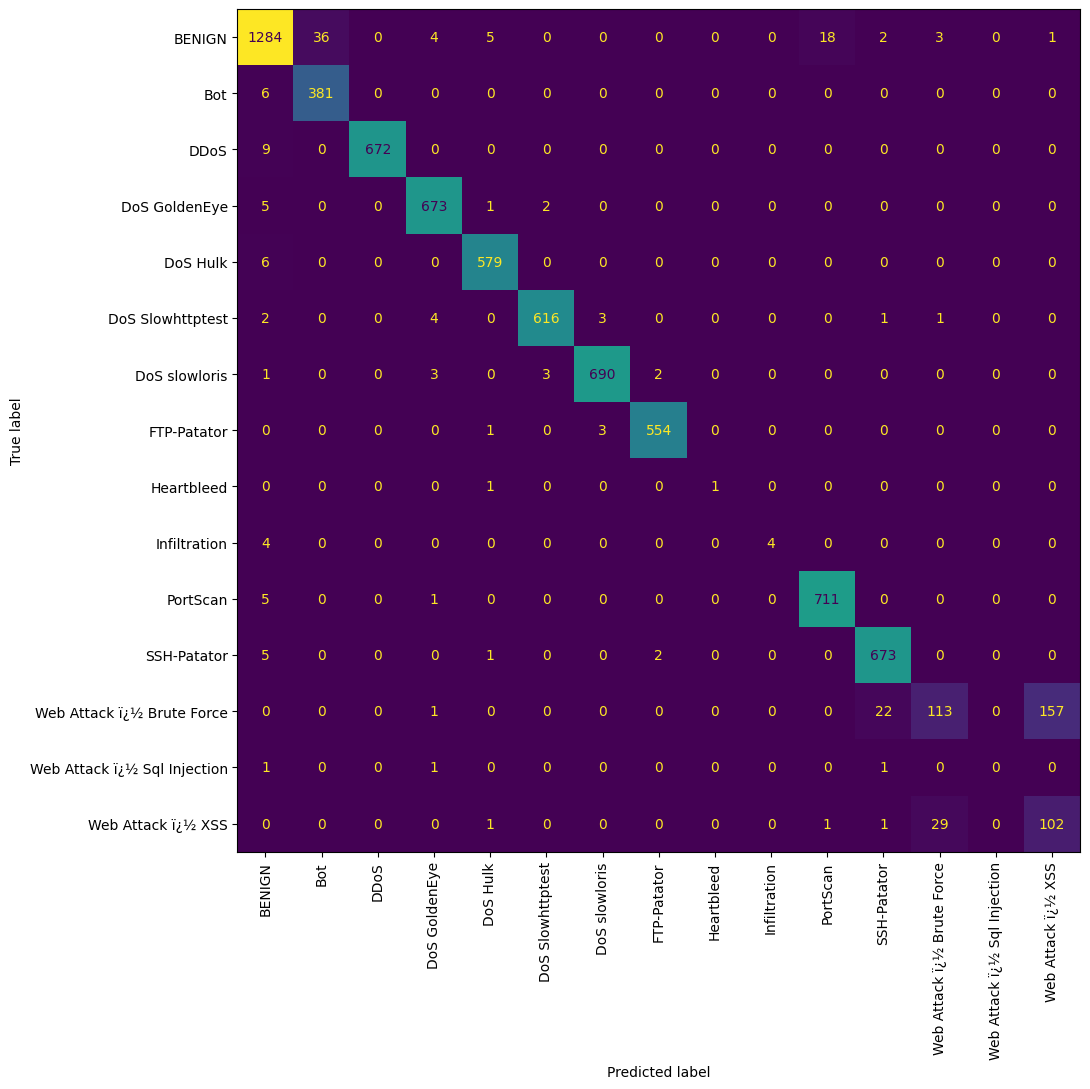

PILOT test metrics (not independent holdout):
{
  "accuracy": 0.951950330678904,
  "macro_f1": 0.8107862557481416,
  "weighted_f1": 0.95100370093577,
  "xss_f1": 0.5177664974619289,
  "xss_recall": 0.7611940298507462,
  "attack_recall": 0.9927344782034346,
  "fpr": 0.050997782705099776
}


,precision,recall,f1-score,support,class_accuracy_ovr
attack_class,,,,,
BENIGN,0.9669,0.9490,0.9579,1353.0,0.9847
Bot,0.9137,0.9845,0.9478,387.0,0.9943
DDoS,1.0000,0.9868,0.9933,681.0,0.9988
DoS GoldenEye,0.9796,0.9883,0.9839,681.0,0.9970
DoS Hulk,0.9830,0.9897,0.9864,585.0,0.9978
DoS Slowhttptest,0.9919,0.9825,0.9872,627.0,0.9978
DoS slowloris,0.9914,0.9871,0.9892,699.0,0.9980
FTP-Patator,0.9928,0.9928,0.9928,558.0,0.9989
Heartbleed,1.0000,0.5000,0.6667,2.0,0.9999


In [66]:
# This test was already inspected in previous experiments. Use ONLY as exploratory pilot verification.
test_logits=infer_logits('test')
test_pred=apply_bias(test_logits,BENIGN_BIAS)
test_metrics=calc(y['test'],test_pred)
report=classification_report(y['test'],test_pred,labels=all_ids,target_names=classes,
                            output_dict=True,zero_division=0)
per_class=pd.DataFrame(report).T.loc[classes].copy()
per_class.index.name='attack_class'
per_class['class_accuracy_ovr']=[float(((y['test']==j)==(test_pred==j)).mean()) for j in all_ids]
per_class.to_csv(OUTPUT/'pilot_test_per_class_metrics.csv')
pd.DataFrame(report).T.to_csv(OUTPUT/'pilot_test_classification_report.csv')
cm=confusion_matrix(y['test'],test_pred,labels=all_ids)
pd.DataFrame(cm,index=classes,columns=classes).to_csv(OUTPUT/'pilot_test_confusion_matrix.csv')
pd.DataFrame({'actual':enc.inverse_transform(y['test']),'predicted':enc.inverse_transform(test_pred)}).to_csv(OUTPUT/'pilot_test_predictions.csv',index=False)
fig,ax=plt.subplots(figsize=(13,11))
ConfusionMatrixDisplay(cm,display_labels=classes).plot(ax=ax,xticks_rotation=90,colorbar=False)
plt.tight_layout();fig.savefig(OUTPUT/'pilot_test_confusion_matrix.png',dpi=150);plt.show()
print('PILOT test metrics (not independent holdout):')
print(json.dumps(test_metrics,indent=2));display(per_class.round(4))

## 7. Đóng gói model: checkpoint, preprocessing, manifest, validation/test metrics

In [67]:
# The model's inference contract is: numeric dataframe with ALL 60 input features in exactly this order;
# impute (train median) -> scale (train z-score) -> model -> add BENIGN bias -> argmax -> label encoder.
shutil.copy2(checkpoint_path,OUTPUT/'model.pt')
joblib.dump({'imputer':imputer,'scaler':scaler,'label_encoder':enc,'features':features,
             'feature_variant':variant,'split_sha256':sha},OUTPUT/'preprocessing.joblib')
(OUTPUT/'feature_names.json').write_text(json.dumps(features,ensure_ascii=False,indent=2),encoding='utf8')
(OUTPUT/'class_names.json').write_text(json.dumps(classes,ensure_ascii=False,indent=2),encoding='utf8')
(OUTPUT/'validation_metrics.json').write_text(json.dumps(val_metrics,indent=2),encoding='utf8')
(OUTPUT/'pilot_test_metrics.json').write_text(json.dumps(test_metrics,indent=2),encoding='utf8')
package={
 'model_name':'Feature-Tokenized MultiScale CNN + SE + MHSA + SMOTE (train-only)',
 'architecture':'T4_TokenCNN_SE_MHSA',
 'checkpoint': 'model.pt','preprocessing':'preprocessing.joblib',
 'selected_strategy':SELECTED_STRATEGY,'selected_seed':SELECTED_SEED,
 'benign_logit_bias':BENIGN_BIAS,'n_features':N_FEATURES,'n_classes':K,
 'split_sha256':sha,'label_order':classes,'feature_order':features,
 'model_config':cc,
 'selection_rule':'Preselected from validation-only Pareto audit; test not used to select checkpoint or bias',
 'evaluation_note':'Pilot test previously inspected; NOT a new independent holdout',
 'deployment_note':'Model predicts per completed FLOW feature vector. Raw packet/pcap capture and feature extractor are NOT included.'
}
(OUTPUT/'deployment_manifest.json').write_text(json.dumps(package,indent=2,ensure_ascii=False),encoding='utf8')
# Roundtrip verification: model and preprocess file can be restored and produce identical predictions.
restored=joblib.load(OUTPUT/'preprocessing.joblib')
assert restored['features']==features and restored['split_sha256']==sha
reloaded=torch.load(OUTPUT/'model.pt',map_location='cpu',weights_only=False)
assert reloaded['split_sha256']==sha and reloaded['arch']==ck['arch']
assert set(reloaded['state_dict'])==set(model.state_dict())
print('Deployment package verified:',OUTPUT)
for file in sorted(OUTPUT.iterdir()):
 print(' ',file.name, file.stat().st_size,'bytes')

Deployment package verified: /kaggle/working/nids_outputs/05_V10_SMOTE900_Deployment
  class_names.json 288 bytes
  deployment_manifest.json 2707 bytes
  feature_names.json 1283 bytes
  model.pt 486457 bytes
  pilot_test_classification_report.csv 1289 bytes
  pilot_test_confusion_matrix.csv 904 bytes
  pilot_test_confusion_matrix.png 161410 bytes
  pilot_test_metrics.json 242 bytes
  pilot_test_per_class_metrics.csv 1375 bytes
  pilot_test_predictions.csv 164339 bytes
  preprocessing.joblib 5702 bytes
  validation_metrics.json 244 bytes
